1. Preparación

Traemos las herramientas del programa: una para las tablas, otra para los cálculos y otras para los gráficos.

In [2]:
import numpy as np                 # sirve para hacer cálculos con números
import pandas as pd                # sirve para trabajar con tablas
import matplotlib.pyplot as plt    # sirve para hacer gráficos
import seaborn as sns              # hace los gráficos más bonitos

sns.set_theme(style="whitegrid")   # le pone fondo con cuadrícula a los gráficos

2 Cargar los datos

Qué se analiza: abrimos el archivo de casos de dengue y clima del país y vemos cuántas filas y columnas tiene. Cada fila es una semana. Le decimos al programa que la columna de fechas es una fecha de verdad (no un texto), para poder hacer gráficos del tiempo.

In [3]:
df = pd.read_csv("../data/raw/vectoria_dengue_nacional_real.csv",
                 parse_dates=["fecha_inicio_semana"])   # abre el archivo y reconoce la columna de fechas
print(df.shape)                                         # muestra (filas, columnas)

(574, 12)


3. Primer vistazo

Qué se analiza: miramos las primeras filas y el tipo de cada columna para entender qué tenemos:

fecha_inicio_semana, anio, semana_epi: cuándo es la semana.
provincia, region_climatica, poblacion: datos del país (son iguales en todas las filas).
casos_dengue: casos de dengue en la semana. Es lo que queremos predecir.
tasa_100k: casos por cada 100,000 personas.
lluvia_mm, temp_max_c, temp_min_c, humedad_rel_pct: el clima de la semana.

In [4]:
df.head()    # muestra las primeras 5 filas

,fecha_inicio_semana,anio,semana_epi,provincia,region_climatica,poblacion,casos_dengue,tasa_100k,lluvia_mm,temp_max_c,temp_min_c,humedad_rel_pct
0,2013-12-29,2014,1,Costa Rica,Nacional,5170000,239,4.62,11.0,27.2,19.9,84.9
1,2014-01-05,2014,2,Costa Rica,Nacional,5170000,257,4.97,8.9,27.0,19.7,83.8
2,2014-01-12,2014,3,Costa Rica,Nacional,5170000,184,3.56,4.5,27.1,19.5,81.7
3,2014-01-19,2014,4,Costa Rica,Nacional,5170000,156,3.02,7.7,27.1,19.5,80.0
4,2014-01-26,2014,5,Costa Rica,Nacional,5170000,189,3.66,4.7,27.2,18.7,78.0


In [5]:
df.info()    # muestra el tipo de cada columna y cuántos datos tiene

<class 'pandas.DataFrame'>
RangeIndex: 574 entries, 0 to 573
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   fecha_inicio_semana  574 non-null    datetime64[us]
 1   anio                 574 non-null    int64         
 2   semana_epi           574 non-null    int64         
 3   provincia            574 non-null    str           
 4   region_climatica     574 non-null    str           
 5   poblacion            574 non-null    int64         
 6   casos_dengue         574 non-null    int64         
 7   tasa_100k            574 non-null    float64       
 8   lluvia_mm            574 non-null    float64       
 9   temp_max_c           574 non-null    float64       
 10  temp_min_c           574 non-null    float64       
 11  humedad_rel_pct      574 non-null    float64       
dtypes: datetime64[us](1), float64(5), int64(4), str(2)
memory usage: 53.9 KB


Qué encontramos: la primera fila es la semana del 29 de diciembre de 2013, con 239 casos. Parece raro que sea 2013 si dice anio = 2014. No es un error: las semanas epidemiológicas (semana_epi) pueden empezar en los últimos días del año anterior. Las columnas de números aparecen como int64 o float64, y las de texto como object o str. Todas muestran 574 datos, así que a simple vista no falta nada.

Qué se analiza: antes de analizar, revisamos que los datos estén sanos:

¿Hay casillas vacías?
¿Hay filas repetidas?
¿Las semanas avanzan siempre de 7 en 7 días, sin saltos?
¿Hay columnas que siempre tengan el mismo valor? No sirven para predecir nada.
¿tasa_100k dice lo mismo que casos_dengue?

In [6]:
print("Casillas vacías por columna:")
print(df.isna().sum())                                # cuenta las casillas vacías de cada columna

print("Filas repetidas:", df.duplicated().sum())      # cuenta filas idénticas

# Si todo está bien, cada semana debe estar 7 días después de la anterior
saltos = df["fecha_inicio_semana"].diff().dropna()    # días entre una semana y la siguiente
print("Saltos distintos a 7 días:", (saltos != pd.Timedelta(days=7)).sum())

# Cuántos valores distintos tienen estas columnas (si es 1, siempre es lo mismo)
print(df[["provincia", "region_climatica", "poblacion"]].nunique())

# Qué tanto se parecen casos y tasa (1 = idénticos)
print("Parecido casos vs tasa:", round(df["casos_dengue"].corr(df["tasa_100k"]), 4))

Casillas vacías por columna:
fecha_inicio_semana    0
anio                   0
semana_epi             0
provincia              0
region_climatica       0
poblacion              0
casos_dengue           0
tasa_100k              0
lluvia_mm              0
temp_max_c             0
temp_min_c             0
humedad_rel_pct        0
dtype: int64
Filas repetidas: 0
Saltos distintos a 7 días: 0
provincia           1
region_climatica    1
poblacion           1
dtype: int64
Parecido casos vs tasa: 1.0


Qué encontramos:

Casillas vacías: cero en todas las columnas.
Filas repetidas: cero.
Saltos distintos a 7 días: cero, así que no falta ninguna semana.
Columnas constantes: provincia, region_climatica y poblacion tienen 1 solo valor. Siempre dicen “Costa Rica”, “Nacional” y 5,170,000. No aportan nada.
Casos vs tasa: el parecido es 1.0. La tasa es casi lo mismo que los casos dividido por una cifra fija, así que sobra.

Conclusión: los datos ya vienen limpios. Solo hay que quitar columnas inútiles.

5. Quitar columnas que sobran

Qué se hace: eliminamos las 4 columnas que no aportan: 3 siempre valen lo mismo y 1 repite la información de los casos. Además, ponemos la fecha como “etiqueta” de cada fila (índice), lo que facilita los gráficos del tiempo.

In [7]:
df = df.drop(columns=["provincia", "region_climatica", "poblacion", "tasa_100k"])  # quita las 4 columnas
df = df.set_index("fecha_inicio_semana")                                          # la fecha pasa a ser la etiqueta de cada fila
df.info()                                                                         # comprobamos cómo quedó

<class 'pandas.DataFrame'>
DatetimeIndex: 574 entries, 2013-12-29 to 2024-12-22
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   anio             574 non-null    int64  
 1   semana_epi       574 non-null    int64  
 2   casos_dengue     574 non-null    int64  
 3   lluvia_mm        574 non-null    float64
 4   temp_max_c       574 non-null    float64
 5   temp_min_c       574 non-null    float64
 6   humedad_rel_pct  574 non-null    float64
dtypes: float64(4), int64(3)
memory usage: 35.9 KB


Qué encontramos: quedan 7 columnas (anio, semana_epi, casos_dengue y las 4 del clima) y 574 filas, con fechas del 2013-12-29 al 2024-12-22.

6. Resumen en números

Qué se analiza: vemos para cada columna el promedio, el valor más bajo, el más alto y los valores “del medio”. Sirve para tener una idea de qué tan grandes son los números y si hay valores raros.

In [8]:
clima = ["lluvia_mm", "temp_max_c", "temp_min_c", "humedad_rel_pct"]   # lista con las columnas del clima
df[["casos_dengue"] + clima].describe().round(1)                       # resumen de casos y clima

,casos_dengue,lluvia_mm,temp_max_c,temp_min_c,humedad_rel_pct
count,574.0,574.0,574.0,574.0,574.0
mean,268.6,52.0,27.8,21.1,83.7
std,304.2,57.6,1.7,0.9,7.7
min,12.0,0.0,24.4,18.4,61.8
25%,71.0,13.6,26.7,20.5,79.4
50%,156.0,38.5,27.4,21.2,86.7
75%,328.0,75.4,28.7,21.8,89.3
max,1749.0,625.2,33.0,23.2,94.9


Análisis:

Casos: el promedio (269) es mucho más alto que la mediana (156). Eso quiere decir que hay pocas semanas con muchísimos casos que “jalan” el promedio hacia arriba. El máximo (1,749) es más de 6 veces el promedio.
Lluvia: pasa lo mismo, con promedio 52 mm y máximo de 625 mm. Hay semanas con lluvia extrema. También hay semanas con 0 mm.
Temperaturas: casi no cambian: la máxima va de 24 a 33 °C y la mínima de 18 a 23 °C. Son rangos chicos, pero ya veremos que ese cambio pequeño importa.
Humedad: siempre es alta (promedio 84 %), como corresponde a un país tropical.

7. Casos de dengue a través del tiempo

Qué se analiza: dibujamos cuántos casos hubo cada semana y cuántos por año. Así vemos los brotes: épocas en que los casos se disparan mucho más de lo normal.

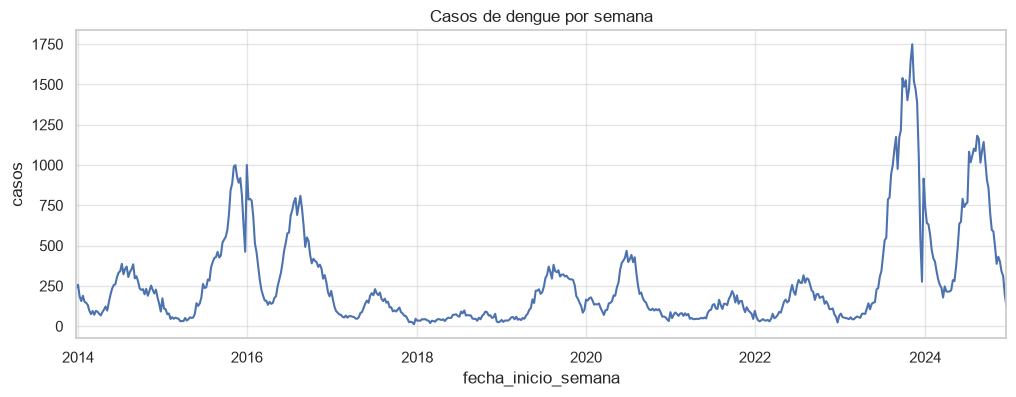

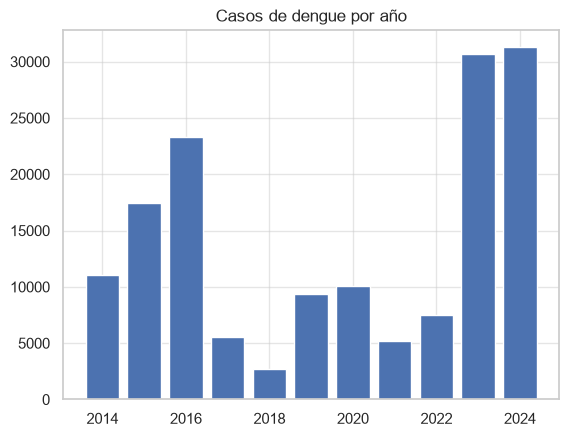

In [9]:
df["casos_dengue"].plot(figsize=(12, 4), title="Casos de dengue por semana")   # línea de casos por semana
plt.ylabel("casos")                                                            # nombre del eje vertical
plt.show()

por_anio = df.groupby("anio")["casos_dengue"].sum()   # suma los casos de cada año
plt.bar(por_anio.index, por_anio.values)              # una barra por año
plt.title("Casos de dengue por año")
plt.show()

Gráfico de líneas: se ven subidas y bajadas que se repiten cada año, y tres picos muy altos. El mayor es de 1,749 casos en la semana del 12 de noviembre de 2023.
Análisis:

Hay tres años de brote: 2016, 2023 y 2024. 2023 y 2024 son los peores, con más de 30,000 casos cada uno, casi 6 veces los de un año bajo como 2021.
El año más bajo es 2018 (2,735 casos) y el más alto, 2024 (31,259).
Después de cada brote los casos bajan mucho (2016 → 2017 y 2018). Esto tiene sentido: tras un brote, mucha gente ya tuvo la enfermedad.
Para un modelo que predice casos, esto es un reto: los brotes son poco frecuentes y mucho más grandes que lo normal.

8. ¿Cómo se reparten los casos?

Qué se analiza: dibujamos cuántas semanas tuvieron pocos casos y cuántas tuvieron muchos. Luego lo repetimos aplicando el logaritmo, un truco matemático que achica los números muy grandes para que los brotes no tapen todo lo demás. Lo usaremos para comparar casos con clima.

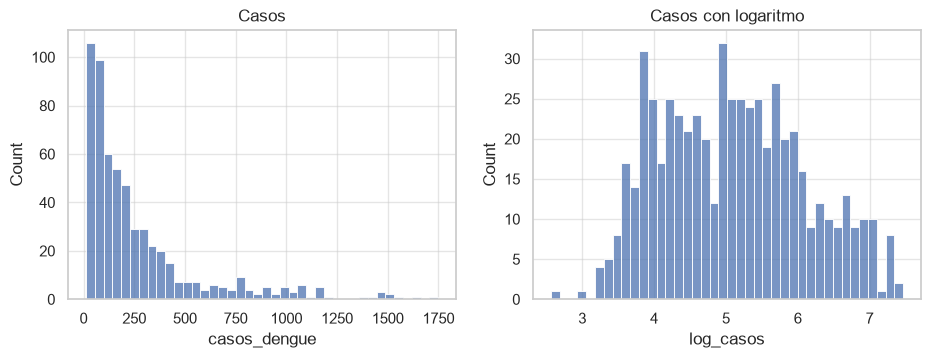

Desparejo, casos: 2.17
Desparejo, con logaritmo: 0.23


In [10]:
df["log_casos"] = np.log1p(df["casos_dengue"])   # crea una columna nueva con los casos "achicados"

fig, ejes = plt.subplots(1, 2, figsize=(11, 3.5))                  # espacio para 2 gráficos lado a lado
sns.histplot(df["casos_dengue"], bins=40, ax=ejes[0])              # gráfico de los casos normales
ejes[0].set_title("Casos")
sns.histplot(df["log_casos"], bins=40, ax=ejes[1])                 # gráfico de los casos achicados
ejes[1].set_title("Casos con logaritmo")
plt.show()

# Qué tan desparejo está cada gráfico (0 = parejo)
print("Desparejo, casos:", round(df["casos_dengue"].skew(), 2))
print("Desparejo, con logaritmo:", round(df["log_casos"].skew(), 2))

El primer gráfico tiene muchas barras altas a la izquierda y una “cola” larga hacia la derecha. El segundo se ve más parejo y en forma de campana. El número de “desparejo” baja de 2.17 a 0.23.

Análisis: casi todas las semanas tienen pocos casos (menos de 330) y muy pocas tienen muchísimos. Con el logaritmo esa diferencia se reduce y los datos quedan más fáciles de comparar. Por eso en los pasos 11 y 12 usamos log_casos.

9. Casos según el mes del año

Qué se analiza: vemos si los casos suben en ciertos meses. Cada caja muestra cómo se comportaron los casos de ese mes en todos los años. La línea del medio es el valor típico.

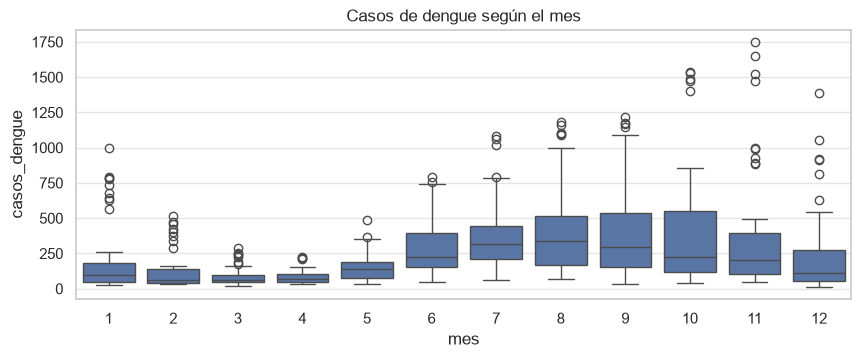

mes
1     213.0
2     132.0
3      89.0
4      86.0
5     153.0
6     287.0
7     383.0
8     431.0
9     412.0
10    406.0
11    389.0
12    236.0
Name: casos_dengue, dtype: float64


In [11]:
df["mes"] = df.index.month                 # saca el número del mes (1 a 12) de la fecha

plt.figure(figsize=(10, 3.5))
sns.boxplot(data=df, x="mes", y="casos_dengue")   # una caja por mes
plt.title("Casos de dengue según el mes")
plt.show()

print(df.groupby("mes")["casos_dengue"].mean().round(0))   # promedio de casos de cada mes

Análisis: el dengue tiene una época fija en el año. Los casos son más bajos en marzo y abril (unos 86 a 89 por semana) y suben desde mayo y junio, cuando empiezan las lluvias. El punto más alto es agosto (431), y se mantiene alto hasta noviembre. Después baja en diciembre. Esto quiere decir que el modelo puede aprender que las semanas de julio a noviembre son de riesgo, y que semana_epi es una columna útil.

10. Clima: ¿hay valores muy raros?

Qué se analiza: dibujamos una caja por cada variable del clima. Los puntitos sueltos fuera de la caja son valores muy distintos al resto (llamados valores atípicos). Después vemos las 5 semanas más lluviosas para saber si son errores o eventos reales.

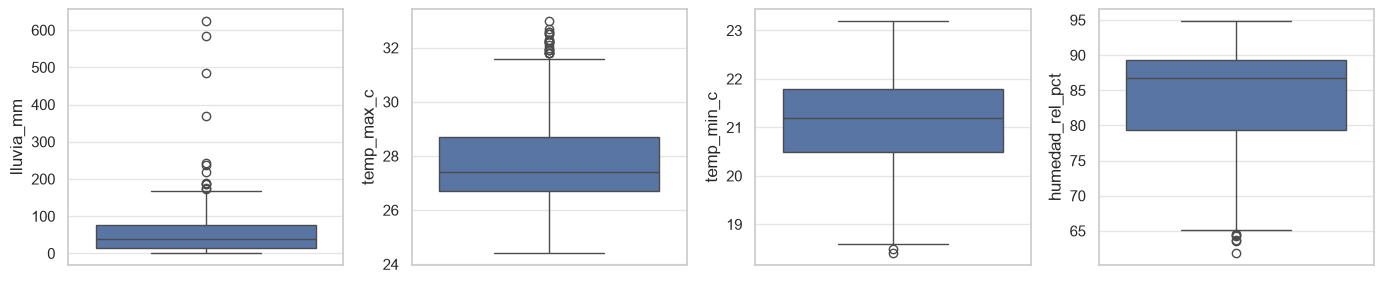

In [12]:
fig, ejes = plt.subplots(1, 4, figsize=(14, 3))     # espacio para 4 gráficos
for eje, variable in zip(ejes, clima):              # repite para cada variable del clima
    sns.boxplot(y=df[variable], ax=eje)             # dibuja su caja
plt.tight_layout()                                  # acomoda los gráficos para que no se encimen
plt.show()

In [13]:
df.nlargest(5, "lluvia_mm")[["lluvia_mm", "casos_dengue"]]   # las 5 semanas con más lluvia

,lluvia_mm,casos_dengue
fecha_inicio_semana,,
2024-05-26,625.2,489
2020-11-01,583.6,106
2024-11-10,483.4,387
2017-10-01,368.0,98
2024-06-02,242.4,636


La lluvia tiene 12 puntos sueltos, la temperatura máxima 21, la humedad 6 y la temperatura mínima solo 2.
Análisis: son lluvias enormes, pero no son errores. Según el LEEME, coinciden con el huracán Nate (octubre 2017), Eta (noviembre 2020) y la tormenta Sara (noviembre 2024). Por eso no las borramos: son parte de la realidad. Nota también que una semana con muchísima lluvia no trajo muchos casos al instante (por ejemplo, 106 casos en la de Eta). Eso sugiere que la lluvia hace efecto semanas después.

11. ¿Qué tanto se relaciona el clima con los casos?

Qué se analiza: el gráfico de colores muestra qué tanto “suben juntas” dos columnas. Un número cerca de 1 quiere decir que cuando una sube, la otra también. Cerca de 0, que no tienen que ver. Negativo, que cuando una sube la otra baja. Aquí todavía comparamos el clima de la misma semana que los casos.

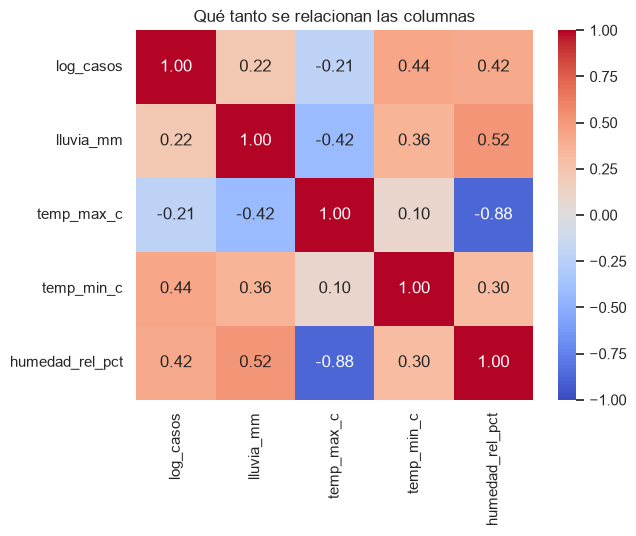

In [14]:
sns.heatmap(df[["log_casos"] + clima].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Qué tanto se relacionan las columnas")
plt.show()

Análisis:

Ninguna relación es fuerte. La mejor es la temperatura mínima (0.44): las noches más cálidas se asocian con más casos.
La temperatura máxima sale negativa, algo que parece raro. Más abajo vemos por qué.
Hay una relación casi opuesta entre temp_max_c y humedad_rel_pct (-0.88): cuando hace más calor de día, la humedad baja. Dicen casi lo mismo, así que no necesitamos fijarnos en las dos.
Una relación débil aquí no significa que el clima no sirva. Falta ver el efecto con retraso.

12. El efecto con retraso

Qué se analiza: el mosquito necesita tiempo para reproducirse y para que la gente se enferme, así que el clima de hoy afecta los casos de semanas después. Comparamos los casos con el clima de hace 0, 1, 2... hasta 12 semanas, y vemos en qué retraso la relación es más fuerte.

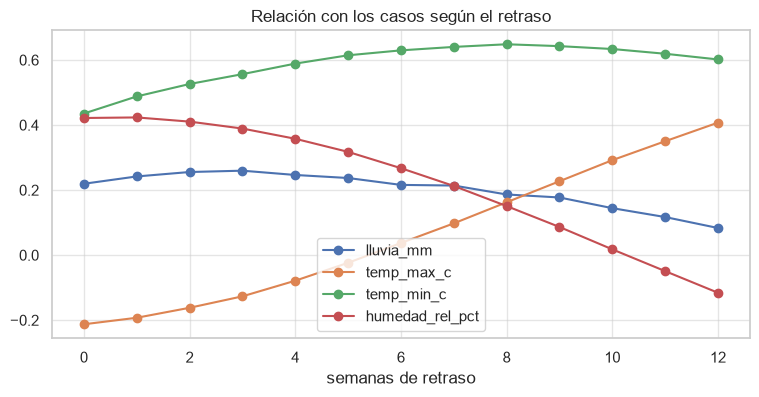

Retraso con mejor relación:
 lluvia_mm           3
temp_max_c         12
temp_min_c          8
humedad_rel_pct     1
dtype: int64
Qué tan fuerte es:
 lluvia_mm          0.26
temp_max_c         0.41
temp_min_c         0.65
humedad_rel_pct    0.42
dtype: float64


In [15]:
retrasos = range(0, 13)    # de 0 a 12 semanas de retraso

# Para cada variable del clima, mueve la columna k semanas y la compara con los casos
tabla = pd.DataFrame(
    {v: [df["log_casos"].corr(df[v].shift(k)) for k in retrasos] for v in clima},
    index=retrasos)

tabla.plot(marker="o", figsize=(9, 4), title="Relación con los casos según el retraso")
plt.xlabel("semanas de retraso")
plt.show()

print("Retraso con mejor relación:\n", tabla.idxmax())   # en qué semana es más fuerte
print("Qué tan fuerte es:\n", tabla.max().round(2))

Análisis:

La temperatura mínima es la mejor pista. Al compararla con el retraso correcto sube de 0.44 a 0.65. Se hace más fuerte desde la semana 0 hasta la 8, y después empieza a bajar. Es decir, las noches cálidas de hace unos 2 meses ayudan a explicar los casos de hoy.
La lluvia es una relación débil (0.26) con 3 semanas de retraso.
La humedad es mejor sin retraso o con 1 semana, y se pierde pasadas unas 8 semanas.
Con temp_max_c, el número mejor cae en el límite de la gráfica (12 semanas), así que no sirve para sacar conclusiones. Probablemente se explique porque el calor del día es máximo en la época seca y 12 semanas después llega la época de más casos, o sea, que es el efecto del calendario y no que el calor cause los casos.


13. Preparación de los datos

Qué se hace: como el clima actúa con retraso, creamos columnas nuevas con el clima de 2, 4, 6 y 8 semanas atrás. Las primeras 8 semanas quedan sin esos datos (no hay clima “anterior”), así que se quitan. Guardamos el resultado en data/processed/ para usarlo en el modelo.

In [16]:
for v in clima:                              # para cada variable del clima
    for k in [2, 4, 6, 8]:                   # y para cada retraso
        df[f"{v}_lag{k}"] = df[v].shift(k)   # crea una columna con el clima de hace k semanas

df = df.dropna()                             # quita las primeras 8 semanas, que quedaron vacías
df.to_csv("../data/processed/dengue_procesado.csv")   # guarda el resultado
print(df.shape)

(566, 25)


Unas conclusiones:
Los datos del país están limpios: 574 semanas, sin casillas vacías, sin repetidos y sin semanas faltantes. Solo se quitaron 4 columnas que sobraban.

Hubo tres brotes de dengue: 2016, 2023 y 2024. Los de 2023 y 2024 son los más grandes (más de 30,000 casos al año).

Los casos siguen una época del año: bajos en marzo y abril, y más altos de julio a noviembre (agosto es el pico).

Pocas semanas tienen muchísimos casos, por eso usamos el logaritmo para compararlos.

Las lluvias extremas son eventos reales (huracanes y tormentas), así que no se eliminaron.

El clima actúa con retraso: la temperatura mínima es la mejor pista, con 6 a 8 semanas de diferencia.

Siguiente paso: usar estos datos para el modelo que predice los casos de las próximas 4 semanas.

15. Cargar los datos

Qué se analiza: abrimos el archivo y miramos cómo es. Cada fila es una semana con un pronóstico, el clima y la acción recomendada. Lo que queremos que el modelo aprenda a adivinar es la columna recomendacion.

Qué significa cada columna:

escenario: del 1 al 5, son 5 versiones de la misma semana (ya vemos por qué).
casos_pred_4sem: casos que se “predicen” para las próximas 4 semanas (simulado).
casos_umbral_endemico: cantidad “normal” de casos para esa época. Si se pasa de ahí, preocupa.
lluvia_14d_mm: lluvia de los últimos 14 días.
temp_max, temp_min, humedad: el clima de la semana.
aegypti_detectado: 1 si se detectó el mosquito Aedes aegypti en una foto (simulado), 0 si no.
recomendacion: la acción a tomar.

In [17]:
acc = pd.read_csv("../data/raw/vectoria_acciones.csv", parse_dates=["fecha_inicio_semana"])   # abre el archivo
print(acc.shape)    # (filas, columnas)
acc.head()          # primeras 5 filas

(2060, 12)


,fecha_inicio_semana,anio,semana_epi,escenario,casos_pred_4sem,casos_umbral_endemico,lluvia_14d_mm,temp_max,temp_min,humedad,aegypti_detectado,recomendacion
0,2017-01-01,2017,1,1,496,1909,35.9,27.0,19.6,84.6,1,monitoreo_normal
1,2017-01-01,2017,1,2,449,1909,35.9,27.0,19.6,84.6,0,monitoreo_normal
2,2017-01-01,2017,1,3,366,1909,35.9,27.0,19.6,84.6,0,monitoreo_normal
3,2017-01-01,2017,1,4,433,1909,35.9,27.0,19.6,84.6,0,monitoreo_normal
4,2017-01-01,2017,1,5,392,1909,35.9,27.0,19.6,84.6,0,monitoreo_normal


In [18]:
acc.info()    # tipo de cada columna y cuántos datos tiene

<class 'pandas.DataFrame'>
RangeIndex: 2060 entries, 0 to 2059
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   fecha_inicio_semana    2060 non-null   datetime64[us]
 1   anio                   2060 non-null   int64         
 2   semana_epi             2060 non-null   int64         
 3   escenario              2060 non-null   int64         
 4   casos_pred_4sem        2060 non-null   int64         
 5   casos_umbral_endemico  2060 non-null   int64         
 6   lluvia_14d_mm          2060 non-null   float64       
 7   temp_max               2060 non-null   float64       
 8   temp_min               2060 non-null   float64       
 9   humedad                2060 non-null   float64       
 10  aegypti_detectado      2060 non-null   int64         
 11  recomendacion          2060 non-null   str           
dtypes: datetime64[us](1), float64(4), int64(6), str(1)
memory usage: 193.3 KB

Qué encontramos: (2060, 12). La primera semana es el 1 de enero de 2017 y aparece repetida varias veces, con el mismo clima pero distinta casos_pred_4sem y distinto aegypti_detectado. Todas las columnas tienen 2,060 datos. 

16. Limpieza y los 5 escenarios

Qué se analiza: revisamos casillas vacías y filas repetidas. Luego averiguamos qué cambia entre los 5 escenarios de una misma semana, contando cuántos valores distintos hay dentro de cada semana.

In [19]:
print("Casillas vacías:", acc.isna().sum().sum())
print("Filas repetidas:", acc.duplicated().sum())
print("Semanas distintas:", acc["fecha_inicio_semana"].nunique())
print(acc.groupby("fecha_inicio_semana").size().value_counts())   # cuántas filas tiene cada semana

# Dentro de una misma semana, ¿cuántos valores distintos hay en cada columna?
por_semana = acc.groupby("fecha_inicio_semana")[["lluvia_14d_mm", "temp_max", "casos_pred_4sem", "aegypti_detectado"]].nunique()
print(por_semana.max())

Casillas vacías: 0
Filas repetidas: 0
Semanas distintas: 412
5    412
Name: count, dtype: int64
lluvia_14d_mm        1
temp_max             1
casos_pred_4sem      5
aegypti_detectado    2
dtype: int64


Casillas vacías: 0. Filas repetidas: 0.
Semanas distintas: 412 (del 1 de enero de 2017 al 24 de noviembre de 2024).
Cada una de las 412 semanas tiene exactamente 5 filas. 412 × 5 = 2,060.
Lluvia y temperatura: 1 valor distinto por semana, o sea que son iguales en los 5 escenarios.
casos_pred_4sem: hasta 5 valores distintos. Cambia entre escenarios.
aegypti_detectado: hasta 2 valores (0 y 1).

Análisis: los datos están limpios. La clave es que cada semana aparece 5 veces casi igual. Solo cambia la predicción (con algo de error) y si se detectó o no el mosquito. Esto es importante: si al dividir los datos en entrenamiento y prueba separamos las filas al azar, la misma semana quedaría en los dos lados, y el modelo “vería” en el entrenamiento casi lo mismo que luego le preguntamos en la prueba. Sacaría una nota falsamente alta.

17. Resumen en números

Qué se analiza: el promedio, el valor del medio (mediana), el mínimo y el máximo de cada columna de números, para ver su tamaño y si hay valores muy raros.

In [20]:
columnas = ["casos_pred_4sem", "casos_umbral_endemico", "lluvia_14d_mm", "temp_max", "temp_min", "humedad"]
acc[columnas].describe().round(1).T                  # resumen, con una fila por columna
print("Filas donde se detectó aegypti:", acc["aegypti_detectado"].mean().round(2))

Filas donde se detectó aegypti: 0.42


Análisis:

Se detectó aegypti en el 42 % de las filas.

casos_pred_4sem tiene el mismo patrón de los casos reales: promedio (1,006) mucho mayor que la mediana (490) y un máximo de 10,021. Hay pocas filas con predicciones enormes (los brotes). Los números son más grandes que en la serie semanal porque parece ser el total de 4 semanas.

La lluvia es de 14 días, por eso sus números son más altos (113 mm de promedio).

18. Las recomendaciones que queremos predecir

Qué se analiza: contamos cuántas veces sale cada recomendación. Si una sale muchísimo y otra muy poco, decimos que las clases están desbalanceadas, y eso complica el entrenamiento.

recomendacion
monitoreo_normal         1213
alerta_sanitaria          379
eliminacion_criaderos     321
fumigacion_focalizada     147
Name: count, dtype: int64
recomendacion
monitoreo_normal         58.9
alerta_sanitaria         18.4
eliminacion_criaderos    15.6
fumigacion_focalizada     7.1
Name: count, dtype: float64


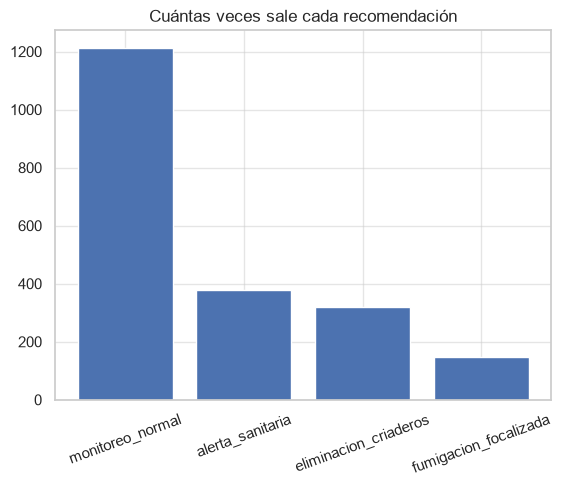

In [21]:
conteo = acc["recomendacion"].value_counts()          # cuántas veces sale cada una
print(conteo)
print((conteo / conteo.sum() * 100).round(1))         # lo mismo en porcentaje

plt.bar(conteo.index, conteo.values)                  # una barra por recomendación
plt.xticks(rotation=20)                               # inclina los nombres para que se lean
plt.title("Cuántas veces sale cada recomendación")
plt.show()

Análisis: el desbalance es claro: monitoreo_normal sale en 6 de cada 10 filas y fumigacion_focalizada solo en 7 de cada 100. Un modelo “flojo” que siempre responda “monitoreo normal” acertaría el 59 % sin aprender nada. Por eso, en este módulo no basta con mirar el porcentaje de aciertos: hay que revisar precisión y recall de cada recomendación

y darle más peso (class weights) a las clases con pocas filas.

19. ¿Qué distingue a cada recomendación?

Qué se analiza: creamos una medida simple: cuántas veces la predicción de casos supera el umbral normal (proporcion). Un 1 significa “justo en el límite”, un 3 significa “el triple de lo normal”. Vemos cómo se reparte según la recomendación y si se detectó el mosquito.

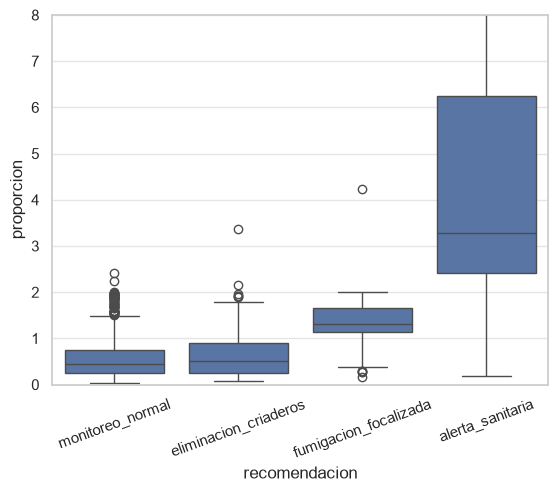

recomendacion
alerta_sanitaria         3.29
eliminacion_criaderos    0.51
fumigacion_focalizada    1.31
monitoreo_normal         0.45
Name: proporcion, dtype: float64
recomendacion
alerta_sanitaria         0.44
eliminacion_criaderos    0.42
fumigacion_focalizada    0.97
monitoreo_normal         0.34
Name: aegypti_detectado, dtype: float64
aegypti_detectado
0     82.0
1    157.0
Name: lluvia_14d_mm, dtype: float64


In [22]:
acc["proporcion"] = acc["casos_pred_4sem"] / acc["casos_umbral_endemico"]   # veces que supera el umbral

sns.boxplot(data=acc, x="recomendacion", y="proporcion")   # una caja por recomendación
plt.ylim(0, 8)                                             # recorta el gráfico para verlo mejor
plt.xticks(rotation=20)
plt.show()

print(acc.groupby("recomendacion")["proporcion"].median().round(2))           # valor típico de cada una
print(acc.groupby("recomendacion")["aegypti_detectado"].mean().round(2))      # cuántas veces hubo aegypti
print(acc.groupby("aegypti_detectado")["lluvia_14d_mm"].mean().round(0))      # lluvia con y sin aegypti

Lluvia promedio sin aegypti: 82 mm. Con aegypti: 157 mm.

Análisis:

Alerta sanitaria: se da cuando la predicción es mucho más alta que lo normal (el triple, en lo típico). Es la más fácil de reconocer.
Fumigación focalizada: se da casi siempre (97 %) cuando se detectó aegypti y los casos pasan algo el umbral. Esa es su señal.
Eliminación de criaderos y monitoreo normal: ambas tienen casos por debajo del umbral y se parecen mucho en esa medida. Lo que las separa es la lluvia y el calor. Probablemente serán las que más se confundan.
La detección de aegypti va con la lluvia: cuando se detectó, la lluvia promedio era casi el doble (157 mm contra 82 mm). Creemos que esto viene de como fueron simulados los datos

In [23]:
def regla(fila):
    # Aplica las reglas del PDF en orden; la primera que se cumple gana
    if fila["casos_pred_4sem"] > 2 * fila["casos_umbral_endemico"]:
        return "alerta_sanitaria"
    if fila["casos_pred_4sem"] > fila["casos_umbral_endemico"] and fila["aegypti_detectado"] == 1:
        return "fumigacion_focalizada"
    if fila["lluvia_14d_mm"] > 80 and fila["temp_max"] > 27:
        return "eliminacion_criaderos"
    return "monitoreo_normal"

acc["regla"] = acc.apply(regla, axis=1)                                   # aplica las reglas a cada fila
print("Coinciden:", (acc["regla"] == acc["recomendacion"]).mean().round(3))
print("No coinciden:", (acc["regla"] != acc["recomendacion"]).sum())

Coinciden: 0.979
No coinciden: 44


Qué encontramos: coinciden el 97.9 % de las filas (2,016 de 2,060). No coinciden 44 filas.

Análisis: las reglas explican casi toda la etiqueta. Las 44 filas distintas son el “ruido” que el LEEME dice que se agregó a propósito (alrededor del 3 % de las etiquetas), para que ningún modelo llegue al 100 % sin esfuerzo. Esto nos dice que el techo realista es cerca de 98 %, así que la meta del 85 % de precisión y recall es alcanzable. También nos dice que la red neuronal debe aprender, en el fondo, estas mismas reglas.

21. ¿Cuándo ocurre cada recomendación?

Qué se analiza: contamos las recomendaciones de cada año. Así vemos si todas aparecen en todos los años o si algunas se concentran en épocas específicas.

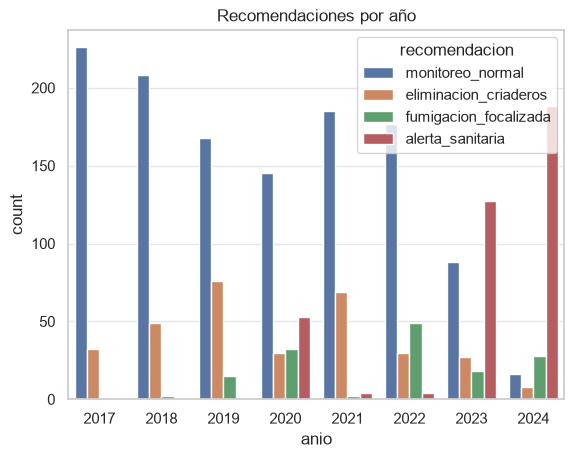

In [24]:
sns.countplot(data=acc, x="anio", hue="recomendacion")   # barras por año, de colores según la recomendación
plt.title("Recomendaciones por año")
plt.show()

Qué encontramos: alerta_sanitaria casi no aparece de 2017 a 2019 (1 vez por año). Sube en 2020 (53), baja en 2021 y 2022 (4 cada año) y se dispara en 2023 (127) y 2024 (188). En 2024 monitoreo_normal casi desaparece (solo 16).

Análisis: las alertas se concentran en los años de brote. Hay una consecuencia práctica: si dividimos el tiempo (entrenar con 2017-2022 y probar con 2023-2024), los datos de prueba serían muy distintos a los de entrenamiento: llenos de alertas que el modelo casi no vio. Por eso el LEEME recomienda separar por semana al azar (con GroupShuffleSplit), y deja la división por años como alternativa para discutir en el informe.

El archivo está limpio: 2,060 filas (412 semanas × 5 escenarios), sin casillas vacías ni repetidas.

Cada semana aparece 5 veces con el mismo clima. Por eso hay que separar entrenamiento y prueba por semana, no por fila.

Las clases están desbalanceadas: monitoreo normal 59 %, alerta 18 %, eliminación de criaderos 16 % y fumigación solo 7 %. Hay que usar pesos por clase y mirar precisión y recall de cada una.

Alerta sanitaria se reconoce por casos muy por encima del umbral; fumigación, por el mosquito detectado; eliminación de criaderos y monitoreo se parecen y serán las más difíciles de separar.

Las alertas se concentran en 2020, 2023 y 2024.

23. Cargar los datos

Qué se analiza: abrimos el archivo y vemos cómo es. Cada fila es un cantón en un año con su total de casos de dengue. Se usará para el mapa de calor de la app. Las columnas son anio, provincia, canton y casos_dengue.

In [25]:
can = pd.read_csv("../data/raw/vectoria_casos_cantonal_anual_real.csv")   # abre el archivo
print(can.shape)    # (filas, columnas)
can.head()          # primeras 5 filas

(422, 4)


,anio,provincia,canton,casos_dengue
0,2013,Alajuela,Alfaro Ruiz,4
1,2013,Alajuela,Atenas,3722
2,2013,Alajuela,Grecia,846
3,2013,Alajuela,Guatuso,30
4,2013,Alajuela,Los Chiles,10


In [26]:
can.info()    # tipo de cada columna y cuántos datos tiene

<class 'pandas.DataFrame'>
RangeIndex: 422 entries, 0 to 421
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   anio          422 non-null    int64
 1   provincia     422 non-null    str  
 2   canton        422 non-null    str  
 3   casos_dengue  422 non-null    int64
dtypes: int64(2), str(2)
memory usage: 13.3 KB


Qué encontramos: (422, 4). Hay 422 filas y 4 columnas. Las primeras filas son de 2013 y de la provincia de Alajuela (Alfaro Ruiz con 4 casos, Atenas con 3,722, Grecia con 846).

24. Limpieza: ¿hay problemas?

Qué se analiza: además de buscar casillas vacías y filas repetidas, revisamos que cada cantón aparezca en todos los años. Si un cantón aparece menos veces de lo normal, hay que saber por qué.

In [27]:
print("Casillas vacías:", can.isna().sum().sum())
print("Filas repetidas:", can.duplicated().sum())
print("Cantones distintos:", can["canton"].nunique())
print(can.groupby("anio")["canton"].nunique())        # cuántos cantones hay en cada año
print("Filas con 0 casos:", (can["casos_dengue"] == 0).sum())

veces = can.groupby("canton").size()                  # cuántos años aparece cada cantón
print(veces[veces < 6])                               # los que aparecen menos de 6 veces
print(can[can["canton"] == "San Jose"])               # el cantón que aparece una sola vez

Casillas vacías: 0
Filas repetidas: 0
Cantones distintos: 72
anio
2013    71
2014    71
2015    71
2016    69
2017    71
2018    69
Name: canton, dtype: int64
Filas con 0 casos: 21
canton
Alfaro Ruiz    5
Alvarado       4
Jimenez        4
San Jose       1
dtype: int64
     anio provincia    canton  casos_dengue
418  2018  San José  San Jose            78


Casillas vacías: 0. Filas repetidas: 0.
Cantones distintos: 72. El LEEME habla de 71.
Cantones por año: 71 en 2013, 2014, 2015 y 2017, y 69 en 2016 y 2018.
Filas con 0 casos: 21.
Aparecen menos de 6 veces: Alvarado (4), Jimenez (4), Alfaro Ruiz (5) y San Jose (1).
San Jose aparece solo en 2018, con 78 casos.



25. Resumen en números

Qué se analiza: el promedio, la mediana, el mínimo y el máximo de casos por cantón y por año.

count     422.0
mean      398.4
std       849.6
min         0.0
25%        18.5
50%        78.0
75%       292.0
max      7272.0
Name: casos_dengue, dtype: float64


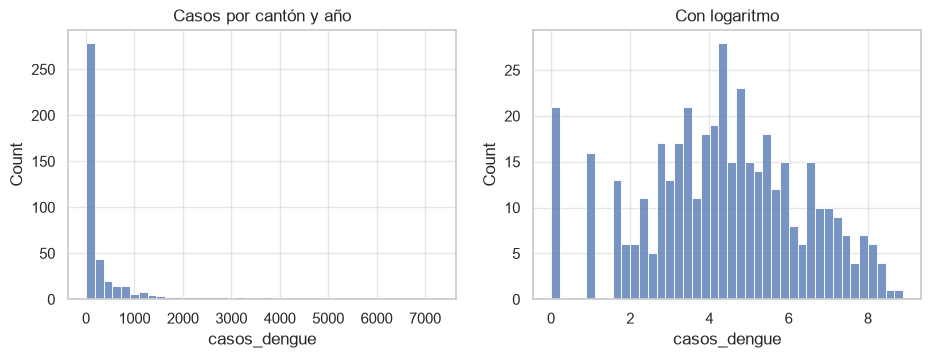

Desparejo, casos: 3.87
Desparejo, con logaritmo: -0.16


In [28]:
print(can["casos_dengue"].describe().round(1))      # resumen de los casos

fig, ejes = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(can["casos_dengue"], bins=40, ax=ejes[0])                # casos normales
ejes[0].set_title("Casos por cantón y año")
sns.histplot(np.log1p(can["casos_dengue"]), bins=40, ax=ejes[1])      # con logaritmo
ejes[1].set_title("Con logaritmo")
plt.show()

print("Desparejo, casos:", round(can["casos_dengue"].skew(), 2))
print("Desparejo, con logaritmo:", round(np.log1p(can["casos_dengue"]).skew(), 2))

El “desparejo” baja de 3.87 a -0.16 con el logaritmo.

Análisis: pasa lo mismo que en las otras partes, pero más fuerte: la mitad de las filas tiene 78 casos o menos, y el promedio (398) está jalado por unos pocos cantones muy afectados. El máximo (7,272) es casi 100 veces la mediana. Por eso en los gráficos y colores conviene usar el logaritmo, porque si no unos pocos cantones se comen todo el color.

26. Casos por año: ¿cuadra con el total del país?

anio
2013    81942
2014    16742
2015    25852
2016    30700
2017     8340
2018     4530
Name: casos_dengue, dtype: int64
      cantones     pais  veces
anio                          
2014   16742.0  11049.0   1.52
2015   25852.0  17485.0   1.48
2016   30700.0  23319.0   1.32
2017    8340.0   5561.0   1.50
2018    4530.0   2735.0   1.66


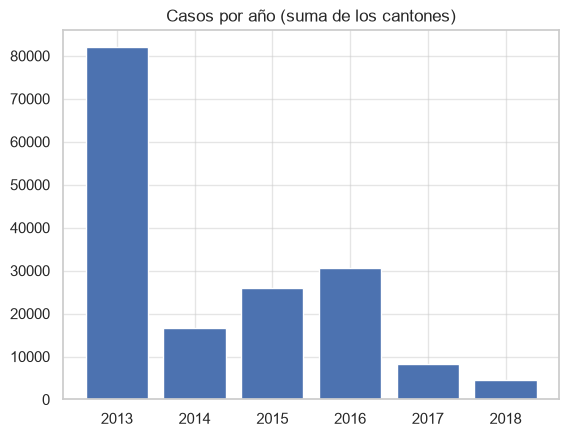

In [29]:
por_anio = can.groupby("anio")["casos_dengue"].sum()      # suma de los cantones por año
print(por_anio)

pais = pd.read_csv("../data/raw/vectoria_dengue_nacional_real.csv").groupby("anio")["casos_dengue"].sum()
comparar = pd.DataFrame({"cantones": por_anio, "pais": pais}).dropna()    # junta las dos sumas
comparar["veces"] = (comparar["cantones"] / comparar["pais"]).round(2)    # cuántas veces es mayor
print(comparar)

plt.bar(por_anio.index, por_anio.values)
plt.title("Casos por año (suma de los cantones)")
plt.show()

Análisis:

La suma de los cantones siempre es mayor que el total del país, entre 1.3 y 1.7 veces. El LEEME lo confirma: en 2013 la suma da 81,942 contra 49,993 del país, y dice que probablemente se debe a que la fuente define “caso” de otra manera.
Aun así, las dos series suben y bajan juntas: ambas tienen un año alto en 2016 y años bajos en 2017 y 2018. O sea, la forma es confiable aunque el número absoluto no lo sea.
2013 fue el año con más casos por mucho: 81,942, casi el triple del segundo (2016).

Provincias y cantones con más casos

provincia
Guanacaste    31.3
Puntarenas    21.8
Limón         15.2
Alajuela      12.3
San José      11.5
Heredia        6.6
Cartago        1.2
Name: casos_dengue, dtype: float64
canton
Santa Cruz       12066
Nicoya           11686
Pococi            9568
Perez Zeledon     9014
Atenas            8020
Sarapiqui         7076
Siquirres         6450
Corredores        6188
Golfito           5964
Carrillo          5940
Name: casos_dengue, dtype: int64
Los 10 primeros suman: 48.8 %


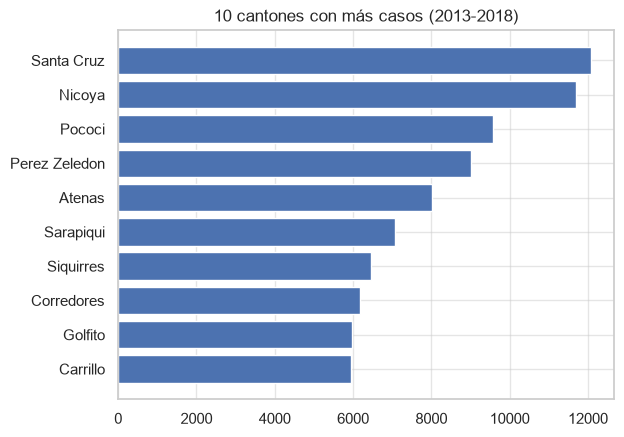

In [30]:
por_prov = can.groupby("provincia")["casos_dengue"].sum().sort_values(ascending=False)   # casos por provincia
print((por_prov / por_prov.sum() * 100).round(1))                                         # en porcentaje

top = can.groupby("canton")["casos_dengue"].sum().sort_values(ascending=False).head(10)   # los 10 cantones con más casos
print(top)
print("Los 10 primeros suman:", round(top.sum() / can["casos_dengue"].sum() * 100, 1), "%")

plt.barh(top.index[::-1], top.values[::-1])      # barras horizontales, el mayor arriba
plt.title("10 cantones con más casos (2013-2018)")
plt.show()

Guanacaste, Puntarenas y Limón (las costas) tienen 68 de cada 100 casos. Cartago casi no tiene (1.2 %).
Santa Cruz y Nicoya, ambos de Guanacaste, son los dos cantones con más casos.
Solo 10 de los 72 cantones tienen casi la mitad de los casos. Los casos están muy concentrados.
Los cantones con menos casos son Alvarado y Jiménez (0 en total) y Alfaro Ruiz (8).

El color dice cuántos casos hay: más oscuro o más rojo, más casos. Hacemos uno por provincia y año, y otro con los 10 cantones más afectados por año. Así vemos cuándo y dónde se concentró el dengue.

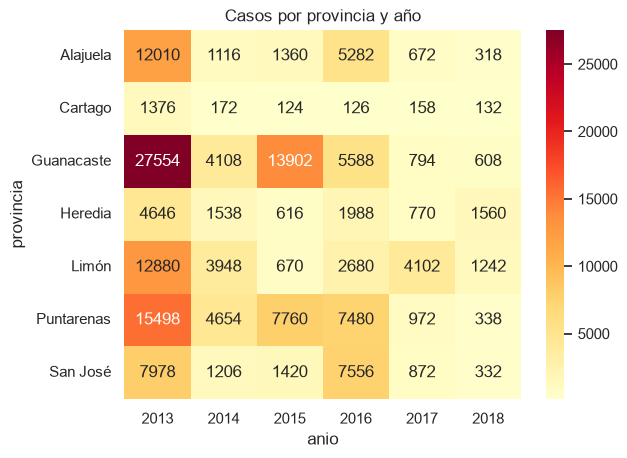

In [31]:
tabla = can.pivot_table(index="provincia", columns="anio", values="casos_dengue", aggfunc="sum")   # filas: provincia, columnas: año
sns.heatmap(tabla, annot=True, fmt=".0f", cmap="YlOrRd")    # tabla con colores y números
plt.title("Casos por provincia y año")
plt.show()

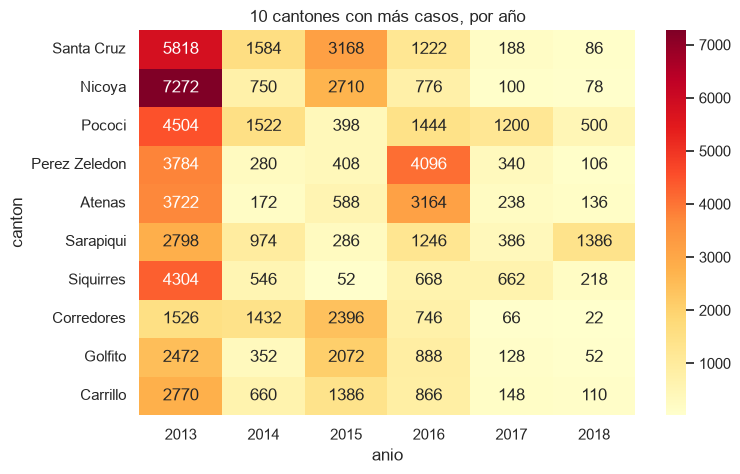

In [32]:
tabla_top = can[can["canton"].isin(top.index)].pivot_table(
    index="canton", columns="anio", values="casos_dengue", aggfunc="sum").loc[top.index]   # solo los 10 cantones con más casos
plt.figure(figsize=(8, 5))
sns.heatmap(tabla_top, annot=True, fmt=".0f", cmap="YlOrRd")
plt.title("10 cantones con más casos, por año")
plt.show()

La columna de 2013 es la más roja: fue un brote enorme, sobre todo en Guanacaste (27,554).
Cada provincia tiene su propio año fuerte. Guanacaste tuvo otro pico en 2015 (13,902). Alajuela y San José se disparan en 2016 (5,282 y 7,556), y dentro de los cantones, Pérez Zeledón (4,096) y Atenas (3,164) alcanzan su máximo ese año. Corredores sube en 2014 y 2015.
Limón va a contracorriente: en 2017, cuando el país estaba bajo, Limón tuvo 4,102 casos, más que en 2016. En 2018 destaca Heredia (1,560), y Sarapiquí (cantón de Heredia) llega a 1,386 ese año.
Cartago se mantiene casi en blanco todos los años.

El archivo tiene 422 filas (cantón y año, 2013 a 2018), sin casillas vacías ni repetidas.
Tiene detalles de calidad que se reportan en el informe: faltan algunas filas (Alvarado y Jiménez en 2016 y 2018, Alfaro Ruiz en 2018), el cantón San José solo aparece en 2018 y los nombres de cantones no llevan tilde mientras los de provincias sí.
La suma de los cantones es entre 1.3 y 1.7 veces mayor que el total del país, por lo que el archivo se usa solo para comparar cantones entre sí, no como cifra oficial.
Los casos están muy concentrados: 10 de 72 cantones tienen el 49 %, y Guanacaste, Puntarenas y Limón tienen el 68 %. Cartago casi no tiene casos.
2013 fue el año con más casos, y cada provincia tiene sus propios años fuertes.
Para los colores del mapa conviene usar el logaritmo, porque unos pocos cantones tienen valores enormes.

provincia y region_climatica: dónde está (Valle Central, Pacífico Norte, Pacífico Central/Sur o Caribe).
poblacion: cuánta gente vive ahí.
tasa_100k: casos por cada 100,000 habitantes. Sirve para comparar provincias grandes con pequeñas.

In [33]:
sem = pd.read_csv("../data/raw/vectoria_dengue_semanal.csv", parse_dates=["fecha_inicio_semana"])   # abre el archivo
print(sem.shape)    # (filas, columnas)
sem.head()          # primeras 5 filas

(4382, 12)


,fecha_inicio_semana,anio,semana_epi,provincia,region_climatica,poblacion,casos_dengue,tasa_100k,lluvia_mm,temp_max_c,temp_min_c,humedad_rel_pct
0,2014-01-05,2014,2,Alajuela,Valle Central,1100000,27,2.45,0.0,27.1,18.9,58.1
1,2014-01-12,2014,3,Alajuela,Valle Central,1100000,10,0.91,0.0,27.3,17.6,64.0
2,2014-01-19,2014,4,Alajuela,Valle Central,1100000,32,2.91,0.0,28.7,18.8,59.4
3,2014-01-26,2014,5,Alajuela,Valle Central,1100000,22,2.00,0.0,28.9,19.2,65.4
4,2014-02-02,2014,6,Alajuela,Valle Central,1100000,15,1.36,0.0,29.3,19.0,65.4


In [34]:
sem.info()    # tipo de cada columna y cuántos datos tiene

<class 'pandas.DataFrame'>
RangeIndex: 4382 entries, 0 to 4381
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   fecha_inicio_semana  4382 non-null   datetime64[us]
 1   anio                 4382 non-null   int64         
 2   semana_epi           4382 non-null   int64         
 3   provincia            4382 non-null   str           
 4   region_climatica     4382 non-null   str           
 5   poblacion            4382 non-null   int64         
 6   casos_dengue         4382 non-null   int64         
 7   tasa_100k            4382 non-null   float64       
 8   lluvia_mm            4347 non-null   float64       
 9   temp_max_c           4348 non-null   float64       
 10  temp_min_c           4382 non-null   float64       
 11  humedad_rel_pct      4353 non-null   float64       
dtypes: datetime64[us](1), float64(5), int64(4), str(2)
memory usage: 410.9 KB


In [35]:
print("Casillas vacías por columna:")
print(sem.isna().sum())
print("Filas con algún vacío:", sem.isna().any(axis=1).sum())
print("Filas repetidas:", sem.duplicated().sum())

# Dentro de cada provincia, cada semana debe estar 7 días después de la anterior
ordenado = sem.sort_values(["provincia", "fecha_inicio_semana"])
saltos = ordenado.groupby("provincia")["fecha_inicio_semana"].diff().dropna()
print("Saltos distintos a 7 días:", (saltos != pd.Timedelta(days=7)).sum())

print(sem.groupby("provincia").size())                                          # semanas de cada provincia
print(sem.groupby("provincia")[["region_climatica", "poblacion"]].first())      # región y población de cada una
print("Casos vs tasa:", round(sem["casos_dengue"].corr(sem["tasa_100k"]), 2))

Casillas vacías por columna:
fecha_inicio_semana     0
anio                    0
semana_epi              0
provincia               0
region_climatica        0
poblacion               0
casos_dengue            0
tasa_100k               0
lluvia_mm              35
temp_max_c             34
temp_min_c              0
humedad_rel_pct        29
dtype: int64
Filas con algún vacío: 97
Filas repetidas: 0
Saltos distintos a 7 días: 0
provincia
Alajuela      626
Cartago       626
Guanacaste    626
Heredia       626
Limón         626
Puntarenas    626
San José      626
dtype: int64
                region_climatica  poblacion
provincia                                  
Alajuela           Valle Central    1100000
Cartago            Valle Central     550000
Guanacaste        Pacífico Norte     390000
Heredia            Valle Central     520000
Limón                     Caribe     450000
Puntarenas  Pacífico Central/Sur     500000
San José           Valle Central    1660000
Casos vs tasa: 0.84


Casillas vacías: lluvia_mm 35, temp_max_c 34 y humedad_rel_pct 29 (cerca del 0.7 % cada una). La temperatura mínima no tiene. En total hay 97 filas con algún vacío.
Filas repetidas: 0. Saltos distintos a 7 días: 0.
Cada provincia tiene 626 semanas (7 × 626 = 4,382).

Rellenar los vacíos que estan a proposito

Qué se hace: a cada casilla vacía le ponemos un valor que queda en el medio entre la semana anterior y la siguiente de la misma provincia (esto se llama interpolar). Es mejor que usar el promedio de todo el país, porque Limón llueve el doble que el resto y mezclar provincias daría valores raros. Después comprobamos que el relleno no cambió el comportamiento de los datos.

In [36]:
sem = sem.sort_values(["provincia", "fecha_inicio_semana"])          # ordena por provincia y fecha
vacias = ["lluvia_mm", "temp_max_c", "humedad_rel_pct"]               # columnas que tienen vacíos

antes = sem.groupby("provincia")["lluvia_mm"].mean()                  # lluvia promedio antes de rellenar
sem[vacias] = sem.groupby("provincia")[vacias].transform(lambda s: s.interpolate(limit_direction="both"))
despues = sem.groupby("provincia")["lluvia_mm"].mean()                # lluvia promedio después de rellenar

print("Vacíos después:", sem.isna().sum().sum())
print(pd.DataFrame({"antes": antes, "despues": despues}).round(1))

Vacíos después: 0
            antes  despues
provincia                 
Alajuela     32.2     32.2
Cartago      31.6     31.6
Guanacaste   31.7     31.9
Heredia      39.4     39.3
Limón        66.1     66.2
Puntarenas   38.1     38.2
San José     32.5     32.5


Vacíos después: 0. La lluvia promedio casi no cambió: por ejemplo, Guanacaste pasó de 31.7 a 31.9, Heredia de 39.4 a 39.3 y Limón de 66.1 a 66.2. En las demás no cambió.

Análisis: el relleno funcionó y no alteró los datos, porque eran pocos vacíos y aislados. Es una decisión que vale la pena explicar en el informe: no borramos esas 97 filas (habríamos perdido información), las rellenamos con lo que había alrededor.

Resumen en números

 el promedio, la mediana, el mínimo y el máximo de cada columna de números, y cuántas semanas tuvieron 0 casos.

In [37]:
columnas = ["casos_dengue", "tasa_100k", "lluvia_mm", "temp_max_c", "temp_min_c", "humedad_rel_pct"]
sem[columnas].describe().round(1).T                                    # resumen, una fila por columna
print("Semanas con 0 casos:", (sem["casos_dengue"] == 0).sum())
print(sem.groupby("provincia")["casos_dengue"].apply(lambda s: (s == 0).sum()))   # 0 casos, por provincia

Semanas con 0 casos: 229
provincia
Alajuela        2
Cartago       181
Guanacaste      3
Heredia        35
Limón           2
Puntarenas      1
San José        5
Name: casos_dengue, dtype: int64


Semanas con 0 casos: 229, de las cuales 181 son de Cartago, 35 de Heredia y las demás de 1 a 5 por provincia.

Cartago pasa más de 1 de cada 4 semanas con 0 casos (181 de 626). Casi no hay dengue ahí, así que será muy difícil de predecir.

Comparamos las provincias

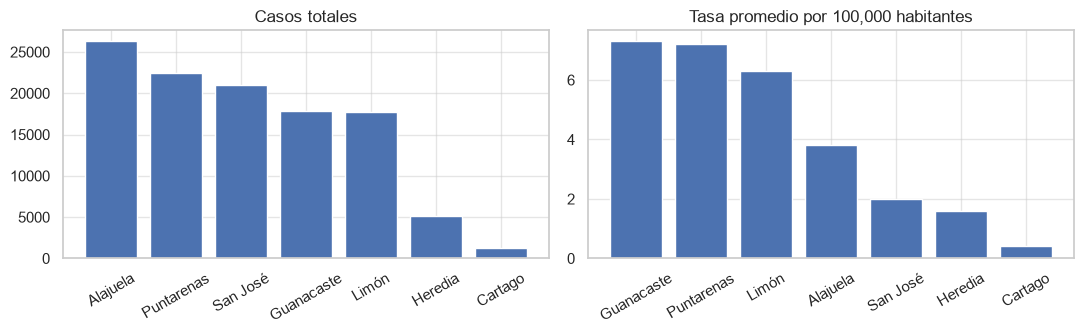

In [38]:
por_prov = sem.groupby("provincia").agg(
    casos_total=("casos_dengue", "sum"),         # casos de todas las semanas
    casos_semana=("casos_dengue", "mean"),       # casos por semana, en promedio
    tasa_100k=("tasa_100k", "mean"),             # tasa promedio
    lluvia_mm=("lluvia_mm", "mean"),
    temp_max_c=("temp_max_c", "mean"),
    temp_min_c=("temp_min_c", "mean"),
    humedad=("humedad_rel_pct", "mean")).round(1)
por_prov.sort_values("casos_total", ascending=False)

fig, ejes = plt.subplots(1, 2, figsize=(11, 3.5))
t = por_prov["casos_total"].sort_values(ascending=False)       # provincias de más a menos casos
r = por_prov["tasa_100k"].sort_values(ascending=False)         # provincias de mayor a menor tasa
ejes[0].bar(t.index, t.values)
ejes[0].set_title("Casos totales")
ejes[1].bar(r.index, r.values)
ejes[1].set_title("Tasa promedio por 100,000 habitantes")
for eje in ejes:
    eje.tick_params(axis="x", rotation=30)                     # inclina los nombres
plt.tight_layout()
plt.show()

Los dos gráficos cuentan historias distintas. Alajuela tiene más casos en total (26,290), pero su tasa es de las más bajas (3.8) porque tiene mucha población. En cambio, Guanacaste, Puntarenas y Limón tienen la tasa más alta (7.3, 7.2 y 6.3): ahí el dengue pega más fuerte por persona. San José tiene muchos casos (20,943), pero la tasa más baja entre las grandes (2.0).
Limón llueve el doble que el resto (66.2 mm contra unos 32-39). Es el clima caribeño, distinto al de las demás regiones.
Cartago es la más fresca (22.6 °C de máxima y 14.3 de mínima) y casi no tiene casos (tasa de 0.4).
Guanacaste es la más calurosa y seca (33.1 °C de máxima y 68.9 % de humedad), y Puntarenas tiene las noches más cálidas (23.2 °C).

Casos por año y por mes

 sumamos los casos de las 7 provincias en cada año, y calculamos cuántos casos hay en promedio por mes. Así vemos los años de brote y la época del año con más dengue.

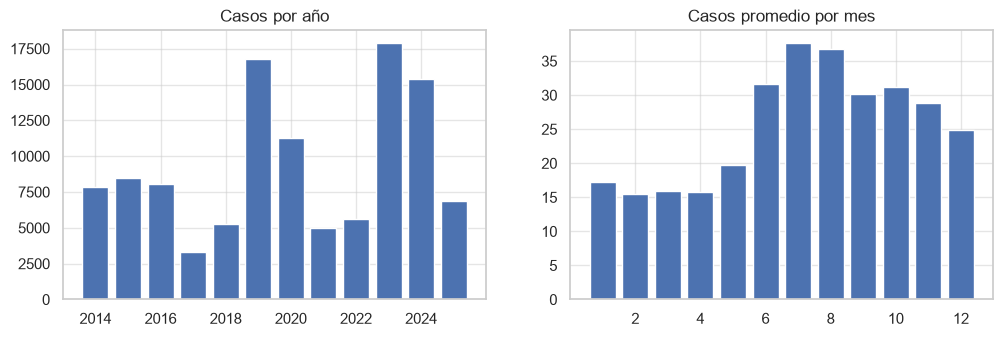

{2014: 7856, 2015: 8458, 2016: 8060, 2017: 3309, 2018: 5242, 2019: 16764, 2020: 11276, 2021: 4967, 2022: 5616, 2023: 17910, 2024: 15412, 2025: 6890}
{1: 17.2, 2: 15.5, 3: 15.9, 4: 15.8, 5: 19.7, 6: 31.6, 7: 37.7, 8: 36.8, 9: 30.2, 10: 31.2, 11: 28.8, 12: 24.9}


In [39]:
por_anio = sem.groupby("anio")["casos_dengue"].sum()       # casos de todo el país por año
sem["mes"] = sem["fecha_inicio_semana"].dt.month           # saca el mes de la fecha
por_mes = sem.groupby("mes")["casos_dengue"].mean()        # casos por semana en promedio, según el mes

fig, ejes = plt.subplots(1, 2, figsize=(12, 3.5))
ejes[0].bar(por_anio.index, por_anio.values)
ejes[0].set_title("Casos por año")
ejes[1].bar(por_mes.index, por_mes.values)
ejes[1].set_title("Casos promedio por mes")
plt.show()
print(por_anio.to_dict())
print(por_mes.round(1).to_dict())

Por mes, el promedio es de unos 16 casos de enero a abril, 19.7 en mayo, 31.6 en junio y sube hasta el pico de 37.7 en julio (36.8 en agosto). Después baja poco a poco: 30.2, 31.2 y 28.8, hasta 24.9 en diciembre.

Análisis:

Hay tres años de brote: 2019, 2023 y 2024, y años bajos como 2017 (3,309) y 2021 (4,967). Es lo que dice el LEEME.
El pico de casos sigue a la llegada de las lluvias (mayo): la subida empieza en mayo y junio, y se mantiene alta hasta noviembre.
No se parece a los datos reales. En el archivo real los brotes fueron 2016, 2023 y 2024, y aquí 2016 ni se nota (8,060) y aparece un 2019 que en la realidad no fue brote. Además los números son mucho más chicos (en 2023 hay 17,910 aquí contra 30,649 en el real).

En el archivo de datos reales llega al año 2024, mientras que este llega al 2025

El efecto de la lluvia con retraso

comparamos los casos con la lluvia de hace 0, 1, 2... hasta 12 semanas. Pero ahora lo hacemos provincia por provincia: si juntáramos las 7 en una sola cuenta, los resultados saldrían engañosos, porque las provincias calientes tienen más casos por ser calientes, no por el retraso.

In [40]:
sem["log_casos"] = np.log1p(sem["casos_dengue"])      # casos "achicados" con logaritmo

for provincia, datos in sem.groupby("provincia"):     # repite para cada provincia
    relacion = [datos["log_casos"].corr(datos["lluvia_mm"].shift(k)) for k in range(13)]
    print(provincia, "- mejor retraso:", int(np.argmax(relacion)), "semanas, relación:", round(max(relacion), 2))

Alajuela - mejor retraso: 3 semanas, relación: 0.27
Cartago - mejor retraso: 4 semanas, relación: 0.1
Guanacaste - mejor retraso: 4 semanas, relación: 0.3
Heredia - mejor retraso: 5 semanas, relación: 0.27
Limón - mejor retraso: 5 semanas, relación: 0.19
Puntarenas - mejor retraso: 3 semanas, relación: 0.29
San José - mejor retraso: 5 semanas, relación: 0.25


Este archivo nos da resultados diferentes al otro archivo
Tiene 4,382 filas (7 provincias × 626 semanas, de 2014 a 2025), sin filas repetidas ni semanas faltantes.
Tenía 97 filas con vacíos en lluvia, temperatura máxima y humedad (cerca del 0.7 % cada una). Se rellenaron con el valor medio entre la semana anterior y la siguiente de la misma provincia, sin alterar los promedios.
Cada provincia tiene su propio clima y nivel de casos: Limón llueve el doble, Cartago es la más fresca y casi no tiene casos, y Guanacaste y Puntarenas tienen la tasa más alta por habitante.
Hay brotes en 2019, 2023 y 2024, y los casos suben de mayo a noviembre con pico en julio.
La lluvia actúa con un retraso de 3 a 5 semanas, y la relación es débil.

In [41]:
sem.to_csv("../data/processed/dengue_provincias_limpio.csv", index=False)   # guarda el archivo ya sin vacíos